In [1]:
from pathlib import Path
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [8]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
import json
with open("results/baseline_evaluation.json", "r") as f:
    baseline_results = json.load(f)

with open("results/resnet50_evaluation.json", "r") as f:
    resnet_results = json.load(f)

print("Baseline results:")
print(baseline_results)

print("\nResNet50 results:")
print(resnet_results)

Baseline results:
{'accuracy': 0.9856020942408377, 'precision': 0.9857577292859131, 'recall': 0.9856020942408377, 'f1_score': 0.9855865833423958}

ResNet50 results:
{'accuracy': 0.9803095834281812, 'precision': 0.980753996772635, 'recall': 0.9803095834281812, 'f1_score': 0.9802793531116512}


In [5]:
comparison_data = {
    "Model": ["Baseline CNN", "ResNet50 Transfer Learning"],
    "Accuracy": [
        baseline_results["accuracy"],
        resnet_results["accuracy"]
    ],
    "Precision": [
        baseline_results["precision"],
        resnet_results["precision"]
    ],
    "Recall": [
        baseline_results["recall"],
        resnet_results["recall"]
    ],
    "F1-Score": [
        baseline_results["f1_score"],
        resnet_results["f1_score"]
    ]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df["Accuracy"] = comparison_df["Accuracy"] * 100
comparison_df["Precision"] = comparison_df["Precision"] * 100
comparison_df["Recall"] = comparison_df["Recall"] * 100
comparison_df["F1-Score"] = comparison_df["F1-Score"] * 100

comparison_df = comparison_df.round(2)

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline CNN,98.56,98.58,98.56,98.56
1,ResNet50 Transfer Learning,98.03,98.08,98.03,98.03


In [6]:
os.makedirs("results", exist_ok=True)

comparison_df.to_csv("results/model_comparison.csv", index=False)

with open("results/model_comparison.json", "w") as f:
    json.dump(comparison_data, f, indent=4)

print("Model comparison saved.")

Model comparison saved.


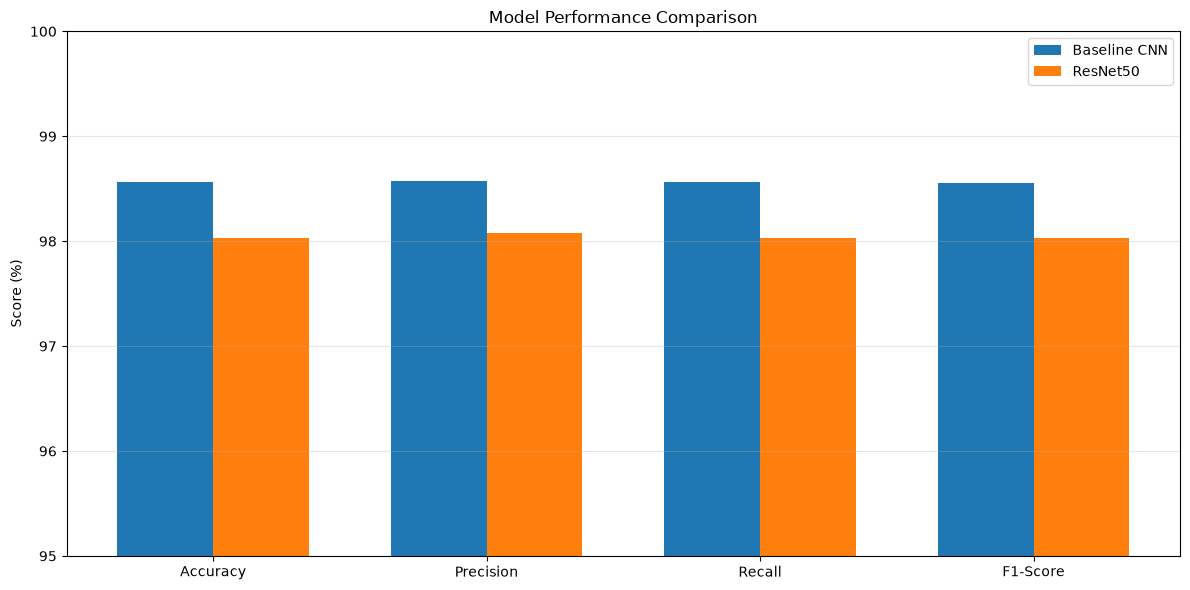

In [9]:
plt.figure(figsize=(12, 6))

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(metrics))
width = 0.35

baseline_values = [
    baseline_results["accuracy"] * 100,
    baseline_results["precision"] * 100,
    baseline_results["recall"] * 100,
    baseline_results["f1_score"] * 100
]

resnet_values = [
    resnet_results["accuracy"] * 100,
    resnet_results["precision"] * 100,
    resnet_results["recall"] * 100,
    resnet_results["f1_score"] * 100
]

plt.bar(x - width/2, baseline_values, width, label="Baseline CNN")
plt.bar(x + width/2, resnet_values, width, label="ResNet50")

plt.xticks(x, metrics)
plt.ylabel("Score (%)")
plt.title("Model Performance Comparison")
plt.ylim(95, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

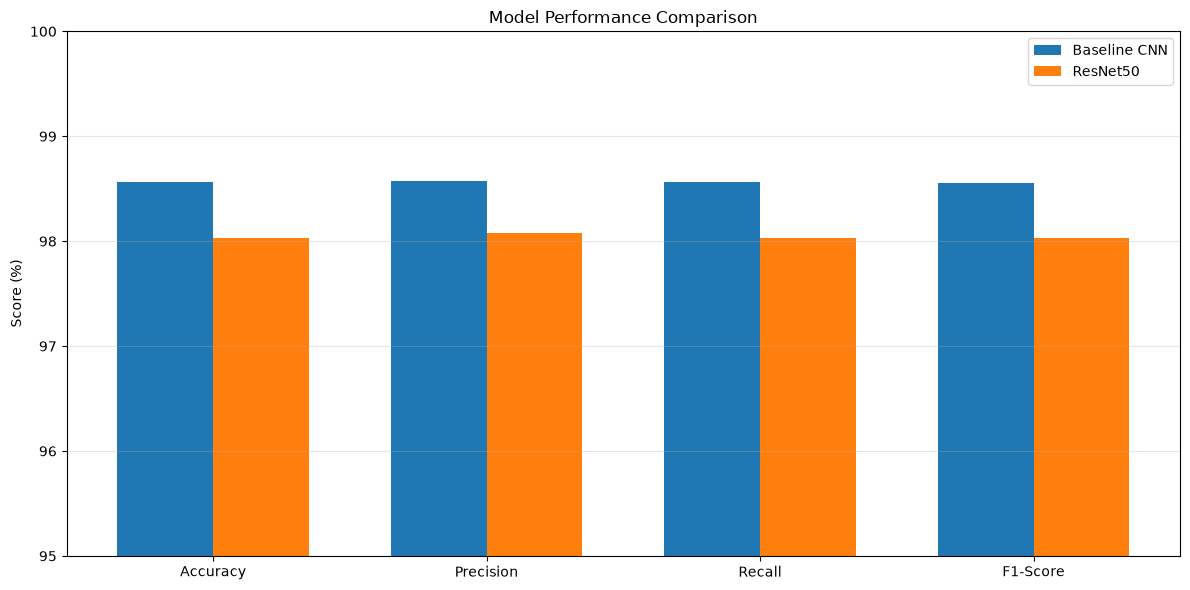

Comparison plot saved to results/model_comparison.png


In [10]:
plt.figure(figsize=(12, 6))

plt.bar(x - width/2, baseline_values, width, label="Baseline CNN")
plt.bar(x + width/2, resnet_values, width, label="ResNet50")

plt.xticks(x, metrics)
plt.ylabel("Score (%)")
plt.title("Model Performance Comparison")
plt.ylim(95, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("results/model_comparison.png", dpi=300)
plt.show()

print("Comparison plot saved to results/model_comparison.png")

In [11]:
if baseline_results["accuracy"] > resnet_results["accuracy"]:
    final_model = "Baseline CNN"
    final_model_path = "models/best_baseline_model.keras"
else:
    final_model = "ResNet50"
    final_model_path = "models/best_resnet50_model.keras"

print("Final selected model:", final_model)
print("Model path:", final_model_path)

Final selected model: Baseline CNN
Model path: models/best_baseline_model.keras


In [12]:
final_model_choice = {
    "final_model": final_model,
    "model_path": final_model_path,
    "reason": "Selected based on highest validation accuracy and overall evaluation metrics."
}

with open("results/final_model_choice.json", "w") as f:
    json.dump(final_model_choice, f, indent=4)

print("Final model choice saved.")
print(final_model_choice)

Final model choice saved.
{'final_model': 'Baseline CNN', 'model_path': 'models/best_baseline_model.keras', 'reason': 'Selected based on highest validation accuracy and overall evaluation metrics.'}
